# 05 · The onboarding tree: from a few answers to a preset

A new household answers a few questions; a decision tree walks those answers to one of the presets from notebook 04.
This replaces the app's current questionnaire, and the household is never asked about individual flows (CableLabs
guidance).

**Method: Smullen et al. 2020 (S20), adapted.** S20 profiles people with decision trees and chooses the number of
profiles by a budget of questions against accuracy. Here:

- **Input:** the household's answers to the 27 candidate questions (notebook 02), each coded in its option order
  (e.g. never < ask < fine), so the tree can split "never or ask" vs "fine".
- **Two ways to choose a leaf's preset:**
  - *cluster label*: the most common profile among the training households in that leaf (S20's profiling target);
  - *best match*: the preset whose rules best match the decisions of the training households in that leaf. This
    targets what matters (the household's own decisions) instead of the cluster label.
- **Measure:** on held-out households (5-fold cross-validation), how often the chosen preset's rules equal the
  household's own decisions, on all items and on the 52 real-device items; the number of questions asked (distinct
  questions on the household's path).
- **Baselines:** *one preset for everyone* (the overall majority, compressed to 15 rules the same way as notebook 04),
  and the *ceiling* (each household gets its own profile's preset, which no questionnaire can beat).

S20 used conditional inference trees (R); here scikit-learn's CART trees, limited by depth and a minimum leaf size, with
**balanced class weights** so small profiles are not ignored (without them, a profile of 4% of households is never
reached, even though a question identifies its households).

**A caveat:** the profiles were built from all households (notebook 03), including the ones held out here, so the
evaluation is slightly optimistic. With 5,000 households the effect is small.

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import KFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
items = pd.read_csv(DATA / "items.csv")
D = np.load(DATA / "decisions.npy")
answers = pd.read_csv(DATA / "answers.csv", dtype=str)
QUESTIONS = {q["id"]: q for q in json.loads((DATA / "questions.json").read_text())}
labels = pd.read_csv(DATA / "profiles" / "labels_ward.csv")
CANDIDATES = [int(c[1:]) for c in labels.columns if c.startswith("k")]
PRESETS = {k: json.loads((DATA / "presets" / f"presets_k{k}.json").read_text()) for k in CANDIDATES}
PRESET_ITEMS = {k: np.load(DATA / "presets" / f"preset_items_k{k}.npy") for k in CANDIDATES}
real = items.in_corpus.to_numpy()
FIELDS = ["data_type", "purpose", "action", "source", "handling_context"]
print(f"{len(answers):,} households, {len(QUESTIONS)} candidate questions, presets for k = {CANDIDATES}")

5,000 households, 27 candidate questions, presets for k = [4, 8, 12, 16, 20, 24]


## Settings

In [2]:
DEPTHS = [2, 3, 4, 5, 6, 7]         # a path asks at most this many questions
MIN_LEAF = 25                        # households per leaf, so no preset is chosen from a handful of people
MAX_QUESTIONS = 7                    # the onboarding budget
CHOSEN_K = 8                         # team decision: fewer presets are easier to name and explain; None = choose automatically
CLASS_WEIGHT = "balanced"            # weight small profiles up, so the tree spends splits on them too (otherwise a 4% profile is never reached)
FOLDS = 5
SEED = 0

## Answers as numbers

Each answer becomes its position in the question's option list (`data/questions.json`).

In [3]:
QIDS = list(QUESTIONS)
X = np.stack([answers[q].map({v: i for i, v in enumerate(QUESTIONS[q]["options"])}).to_numpy() for q in QIDS], axis=1).astype(float)
assert not np.isnan(X).any(), "an answer is not one of its question's options"
pd.DataFrame({"question": QIDS, "options (in order)": [" < ".join(QUESTIONS[q]["options"]) for q in QIDS]}).set_index("question").head(8)

,options (in order)
question,
devices,1-3 < 4-7 < 8-15 < 16+
household_size,1 < 2 < 3-4 < 5+
age_band,18-29 < 30-44 < 45-64 < 65+
children,yes < no
concern,1 < 2 < 3 < 4 < 5
trust_maker,1 < 2 < 3 < 4 < 5
data_content,never < ask < fine
data_location,never < ask < fine


## Baseline: one preset for everyone

The overall majority decision per item, compressed into 15 rules with the same tree settings as notebook 04.

In [4]:
XI = pd.get_dummies(items[FIELDS]).to_numpy().astype(np.float32)
weights = np.where(real, 5.0, np.where(items.plausible, 1.0, 0.1))
def compress(decisions):
    return DecisionTreeClassifier(max_leaf_nodes=15, random_state=0).fit(XI, decisions, sample_weight=weights).predict(XI).astype(np.uint8)

folds = list(KFold(FOLDS, shuffle=True, random_state=SEED).split(X))
one = []
for tr, te in folds:
    preset = compress(np.array([np.bincount(col, minlength=5).argmax() for col in D[tr].T]))
    one.append({"match_all": (D[te] == preset).mean(), "match_real": (D[te][:, real] == preset[real]).mean()})
one = pd.DataFrame(one).mean()
one.round(3)

match_all     0.695
match_real    0.828
dtype: float64

## Trees for every k and depth

In [5]:
def questions_asked(tree, Xt):
    # Distinct questions on each household's path through the tree.
    path = tree.decision_path(Xt); feature = tree.tree_.feature
    return np.array([len({feature[n] for n in path.indices[path.indptr[i]:path.indptr[i + 1]] if feature[n] >= 0}) for i in range(len(Xt))])

def best_match(tree, Xtr, Dtr, preset_items):
    # For each leaf, the preset whose rules best match its training households' decisions.
    leaf = tree.apply(Xtr)
    return {int(L): int(np.argmax([(Dtr[leaf == L] == preset_items[c]).mean() for c in range(len(preset_items))])) for L in np.unique(leaf)}

rows = []
for k in CANDIDATES:
    y, P = labels[f"k{k}"].to_numpy(), PRESET_ITEMS[k]
    for depth in DEPTHS:
        for fold, (tr, te) in enumerate(folds):
            tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=MIN_LEAF, class_weight=CLASS_WEIGHT, random_state=SEED).fit(X[tr], y[tr])
            by_label = tree.predict(X[te])
            mapping = best_match(tree, X[tr], D[tr], P)
            by_match = np.array([mapping[int(L)] for L in tree.apply(X[te])])
            asked = questions_asked(tree, X[te])
            for how, chosen in [("cluster label", by_label), ("best match", by_match)]:
                rows.append({"k": k, "depth": depth, "fold": fold, "assignment": how,
                             "right profile": (chosen == y[te]).mean(),
                             "match_all": (P[chosen] == D[te]).mean(),
                             "match_real": (P[chosen][:, real] == D[te][:, real]).mean(),
                             "ceiling_real": (P[y[te]][:, real] == D[te][:, real]).mean(),
                             "questions (avg)": asked.mean(), "questions (max)": asked.max()})
cv = pd.DataFrame(rows).groupby(["assignment", "k", "depth"]).mean(numeric_only=True).drop(columns="fold")
cv.loc["best match"].round(3)

right profile  match_all  match_real  ceiling_real  questions (avg)  \
k  depth                                                                        
4  2              0.499      0.710       0.837         0.845            2.000   
   3              0.530      0.714       0.838         0.845            3.000   
   4              0.530      0.717       0.845         0.845            4.000   
   5              0.539      0.717       0.845         0.845            4.828   
   6              0.538      0.717       0.845         0.845            5.587   
   7              0.535      0.717       0.846         0.845            6.144   
8  2              0.300      0.699       0.835         0.854            2.000   
   3              0.327      0.703       0.842         0.854            3.000   
   4              0.369      0.713       0.848         0.854            3.946   
   5              0.377      0.716       0.851         0.854            4.799   
   6              0.374      0.717       0.851         0.854            5.616   
   7              0.376      0.717       0.851         0.854            6.377   
12 2              0.187      0.711       0.842         0.858            2.000   
   3              0.235      0.717       0.845         0.858            3.000   
   4              0.256      0.721       0.849         0.858            3.910   
   5              0.267      0.723       0.853         0.858            4.760   
   6              0.264      0.723       0.854         0.858            5.548   
   7              0.272      0.724       0.854         0.858            6.243   
16 2              0.180      0.709       0.832         0.864            2.000   
   3              0.213      0.714       0.848         0.864            3.000   
   4              0.195      0.719       0.850         0.864            3.992   
   5              0.236      0.722       0.853         0.864            4.848   
   6              0.240      0.724       0.855         0.864            5.571   
   7              0.241      0.724       0.855         0.864            6.250   
20 2              0.176      0.709       0.835         0.863            2.000   
   3              0.178      0.714       0.849         0.863            3.000   
   4              0.183      0.719       0.851         0.863            3.988   
   5              0.214      0.722       0.852         0.863            4.914   
   6              0.213      0.723       0.854         0.863            5.703   
   7              0.221      0.724       0.854         0.863            6.335   
24 2              0.136      0.706       0.835         0.864            2.000   
   3              0.139      0.713       0.846         0.864            3.000   
   4              0.136      0.719       0.853         0.864            3.988   
   5              0.163      0.721       0.854         0.864            4.876   
   6              0.168      0.722       0.854         0.864            5.682   
   7              0.175      0.722       0.855         0.864            6.360   

          questions (max)  
k  depth                   
4  2                  2.0  
   3                  3.0  
   4                  4.0  
   5                  5.0  
   6                  6.0  
   7                  7.0  
8  2                  2.0  
   3                  3.0  
   4                  4.0  
   5                  5.0  
   6                  6.0  
   7                  7.0  
12 2                  2.0  
   3                  3.0  
   4                  4.0  
   5                  5.0  
   6                  6.0  
   7                  7.0  
16 2                  2.0  
   3                  3.0  
   4                  4.0  
   5                  5.0  
   6                  6.0  
   7                  7.0  
20 2                  2.0  
   3                  3.0  
   4                  4.0  
   5                  5.0  
   6                  6.0  
   7                  7.0  
24 2                  2.0  
   3   

### Accuracy against the number of questions

Each point is one (k, depth). Higher and further left is better; the dashed lines are *one preset for everyone*.

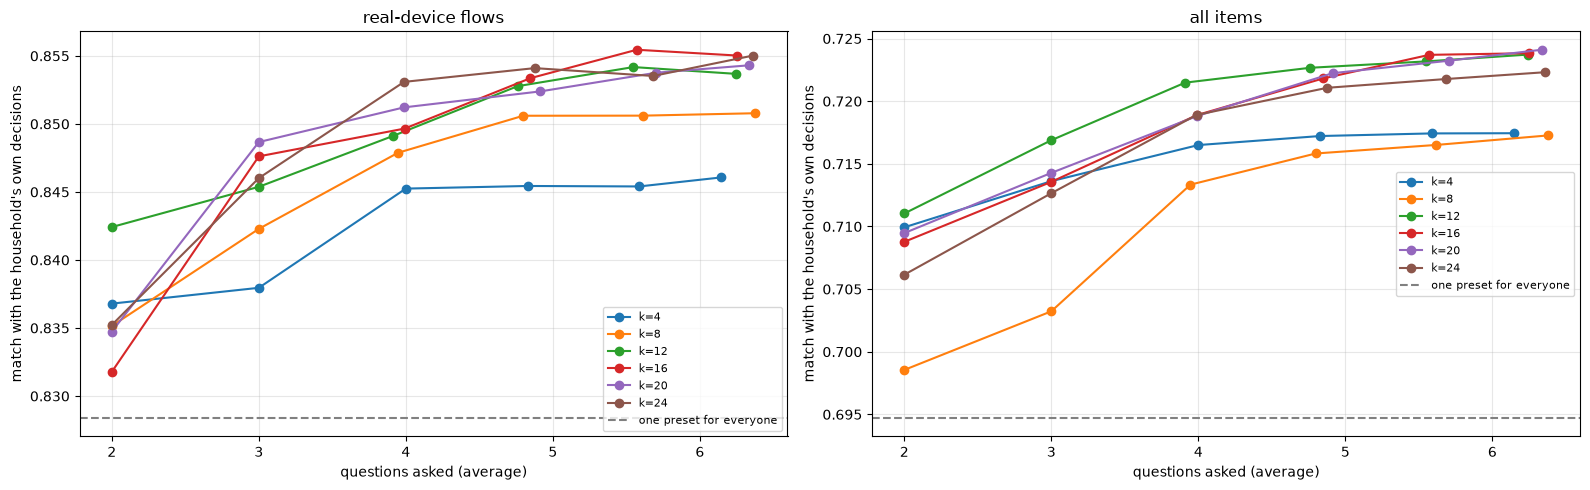

match_all               match_real               right profile  \
assignment best match cluster label best match cluster label    best match   
k                                                                            
4               0.717         0.712      0.845         0.836         0.530   
8               0.713         0.712      0.848         0.848         0.369   
12              0.721         0.714      0.849         0.853         0.256   
16              0.719         0.709      0.850         0.853         0.195   
20              0.719         0.710      0.851         0.852         0.183   
24              0.719         0.709      0.853         0.851         0.136   

                          
assignment cluster label  
k                         
4                  0.543  
8                  0.359  
12                 0.242  
16                 0.183  
20                 0.166  
24                 0.166

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, metric, title in [(axes[0], "match_real", "real-device flows"), (axes[1], "match_all", "all items")]:
    for k in CANDIDATES:
        r = cv.loc[("best match", k)]
        ax.plot(r["questions (avg)"], r[metric], marker="o", label=f"k={k}")
    ax.axhline(one[metric], ls="--", color="grey", label="one preset for everyone")
    ax.set_xlabel("questions asked (average)"); ax.set_ylabel("match with the household's own decisions")
    ax.set_title(title); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
compare = cv.xs(4, level="depth")[["match_all", "match_real", "right profile"]].unstack(0)
compare.round(3)

## Choose k and depth

**Team decision:** `CHOSEN_K = 8`. Eight presets are much easier to name, explain and maintain than 12–24, and up to
seven questions is still a short onboarding. For k = 8 the depth with the highest match within the budget is taken
(fewer questions on a tie). With `CHOSEN_K = None` the automatic rule below is used instead.

Automatic rule, two stages, both in the spirit of asking households as little as possible:

1. For each k, the **fewest questions** whose match on real-device flows is within `DEPTH_TOLERANCE` of that k's best
   (within the budget of `MAX_QUESTIONS`). Extra questions that buy a tenth of a point are not worth asking.
2. Among those, the **fewest presets** within `K_TOLERANCE` of the best (fewer presets to name, explain and maintain).

In [7]:
bm = cv.loc["best match"]
within = bm[bm["questions (max)"] <= MAX_QUESTIONS]
top = within.match_real.max()
DEPTH_TOLERANCE, K_TOLERANCE = 0.003, 0.005
per_k = []
for k, g in within.groupby(level="k"):
    ok = g[g.match_real >= g.match_real.max() - DEPTH_TOLERANCE].sort_values("questions (avg)")
    per_k.append(ok.reset_index().iloc[0])
per_k = pd.DataFrame(per_k)
best = per_k[per_k.match_real >= per_k.match_real.max() - K_TOLERANCE].sort_values(["k", "questions (avg)"]).iloc[0]
best_k, best_depth = int(best.k), int(best.depth)
if CHOSEN_K:
    g = within.loc[CHOSEN_K]
    g = g[g.match_real >= g.match_real.max() - 0.001].sort_values("questions (avg)")
    best_k, best_depth = CHOSEN_K, int(g.index[0])
display(per_k.set_index("k")[["depth", "questions (avg)", "match_real"]].round(3))
chosen = bm.loc[(best_k, best_depth)]
pd.Series({"k": best_k, "depth": best_depth, "questions (avg)": chosen["questions (avg)"], "questions (max)": chosen["questions (max)"],
           "match real-device flows": chosen.match_real, "one preset for everyone": one.match_real, "ceiling": chosen.ceiling_real,
           "match all items": chosen.match_all, "one preset (all items)": one.match_all}).round(3)

,depth,questions (avg),match_real
k,,,
4.0,4.0,4.000,0.845
8.0,4.0,3.946,0.848
12.0,5.0,4.760,0.853
16.0,5.0,4.848,0.853
20.0,5.0,4.914,0.852
24.0,4.0,3.988,0.853


k                          8.000
depth                      5.000
questions (avg)            4.799
questions (max)            5.000
match real-device flows    0.851
one preset for everyone    0.828
ceiling                    0.854
match all items            0.716
one preset (all items)     0.695
dtype: float64

## Confusion matrix

For held-out households (same 5 folds): their own profile (rows) against the preset the tree gives them (columns),
as a share of each row. The diagonal is "the right preset". Off-diagonal mistakes matter less when the two presets
are similar, so the second matrix shows how much each pair of presets agrees on real-device flows.

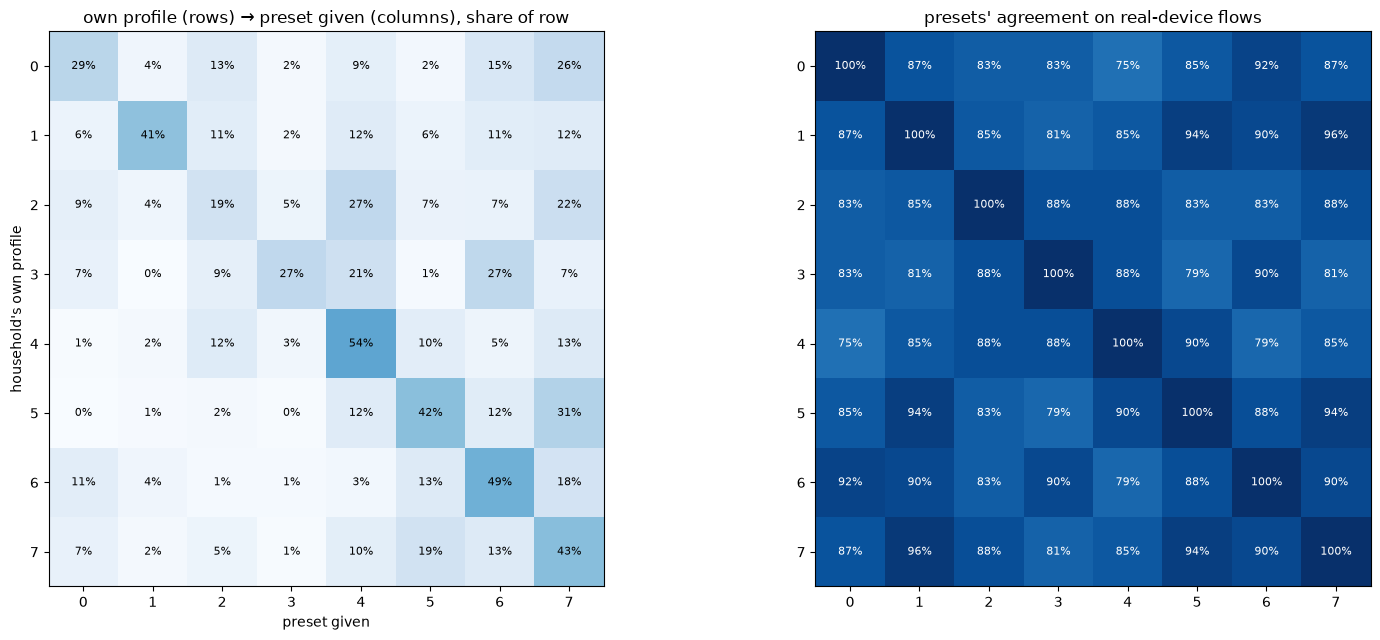

right preset for 38% of households; the preset given agrees with their own profile's preset on 92% of real-device flows on average


In [8]:
from sklearn.metrics import confusion_matrix
truth, given = [], []
for tr, te in folds:
    tr_tree = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=MIN_LEAF, class_weight=CLASS_WEIGHT, random_state=SEED).fit(X[tr], labels[f"k{best_k}"].to_numpy()[tr])
    mp = best_match(tr_tree, X[tr], D[tr], PRESET_ITEMS[best_k])
    truth += list(labels[f"k{best_k}"].to_numpy()[te]); given += [mp[int(L)] for L in tr_tree.apply(X[te])]
cm = confusion_matrix(truth, given, labels=range(best_k), normalize="true")
P_k = PRESET_ITEMS[best_k]
similar = np.array([[(P_k[a][real] == P_k[b][real]).mean() for b in range(best_k)] for a in range(best_k)])
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, m, title, fmt in [(axes[0], cm, "own profile (rows) → preset given (columns), share of row", "{:.0%}"),
                          (axes[1], similar, "presets' agreement on real-device flows", "{:.0%}")]:
    im = ax.imshow(m, cmap="Blues", vmin=0, vmax=1)
    for i in range(best_k):
        for j in range(best_k):
            ax.text(j, i, fmt.format(m[i, j]), ha="center", va="center", fontsize=8, color="white" if m[i, j] > 0.6 else "black")
    ax.set_xticks(range(best_k)); ax.set_yticks(range(best_k)); ax.set_title(title)
axes[0].set_xlabel("preset given"); axes[0].set_ylabel("household's own profile")
plt.tight_layout(); plt.show()
right = np.trace(confusion_matrix(truth, given, labels=range(best_k))) / len(truth)
cost = np.mean([similar[a, b] for a, b in zip(truth, given)])
print(f"right preset for {right:.0%} of households; the preset given agrees with their own profile's preset on {cost:.0%} of real-device flows on average")

Most households do not get exactly their own profile's preset, but the preset they get is usually a similar one: the
average agreement between "own" and "given" preset is high, which is why the match with the household's own decisions
stays close to the ceiling. Profiles the tree never assigns are ones its questions cannot tell apart from a neighbour.

## The chosen tree

Fit on all households; each leaf gets its best-matching preset.

In [9]:
y, P = labels[f"k{best_k}"].to_numpy(), PRESET_ITEMS[best_k]
tree = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=MIN_LEAF, class_weight=CLASS_WEIGHT, random_state=SEED).fit(X, y)
mapping = best_match(tree, X, D, P)
names = {i: p["name"] for i, p in enumerate(PRESETS[best_k]["presets"])}
t = tree.tree_

def show(node=0, indent=""):
    if t.children_left[node] == -1:
        leaf_hh = int(t.n_node_samples[node])
        print(f"{indent}→ preset {mapping[node]}: {names[mapping[node]]}  ({leaf_hh} households)")
        return
    q = QIDS[t.feature[node]]; opts = QUESTIONS[q]["options"]; cut = int(np.floor(t.threshold[node]))
    print(f"{indent}{QUESTIONS[q]['text']}  [{q}]")
    print(f"{indent}  if {' / '.join(opts[:cut + 1])}:"); show(t.children_left[node], indent + "    ")
    print(f"{indent}  if {' / '.join(opts[cut + 1:])}:"); show(t.children_right[node], indent + "    ")
show()

Would you let a smart device use who is home and readings from your home to personalize how it works, without the data leaving your home?  [real_personalized_heating]
  if no:
    May companies use your data for: personalizing what you see?  [purpose_personal]
      if never / ask:
        Would you let a device send how you use it to its maker to improve their products?  [real_usage_improve]
          if no / with_limits:
            How you use the device: may it leave your home?  [data_usage]
              if never / ask:
                Would you let a device send video or audio from your home to its maker's cloud, so you can use it remotely?  [real_video_cloud]
                  if no / with_limits:
                    → preset 0: Careful · no thirdPartyContext, usageData · OK with householdContext  (54 households)
                  if yes:
                    → preset 1: Balanced · no personalization, publicAudience · OK with analyticsAndImprovement, diagnosticsAndMaintenance  (6

In [10]:
usage = pd.Series(questions := [QIDS[f] for f in t.feature if f >= 0]).value_counts()
leaf = tree.apply(X)
asked = questions_asked(tree, X)
print(f"questions used by the tree: {len(usage)} of {len(QIDS)}; households answer {asked.mean():.1f} on average (max {asked.max()})")
print("never used:", ", ".join(q for q in QIDS if q not in usage.index))
usage.rename("splits").to_frame()

questions used by the tree: 9 of 27; households answer 4.9 on average (max 5)
never used: devices, household_size, age_band, children, trust_maker, data_content, data_location, data_identity, data_sensor, data_network, purpose_core, purpose_comms, purpose_diag, purpose_ads, sharing, inference, retention, real_location_home_away


,splits
real_viewing_advertisers,5
purpose_personal,4
real_usage_improve,4
concern,3
real_personalized_heating,2
data_usage,2
real_video_cloud,2
real_profile_ads,2
purpose_analytics,1


## Robustness

1. **Without `concern`.** It is our own question and close to a direct readout of the generator's main trait, so the
   tree may lean on it more than it would with real people. Same settings, `concern` removed.
2. **Noisier answers.** Real people answer less consistently than the synthetic households. At test time, each answer
   is replaced by a random option with probability *p*.

In [11]:
def evaluate(Xall, noise=0.0, rng=None):
    out = []
    for tr, te in folds:
        tr_tree = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=MIN_LEAF, class_weight=CLASS_WEIGHT, random_state=SEED).fit(Xall[tr], y[tr])
        mp = best_match(tr_tree, Xall[tr], D[tr], P)
        Xt = Xall[te].copy()
        if noise:
            flip = rng.random(Xt.shape) < noise
            n_opts = np.array([len(QUESTIONS[q]["options"]) for q in QIDS_USED])
            Xt[flip] = (rng.random(Xt.shape) * n_opts[None, :]).astype(int)[flip]
        chosen = np.array([mp[int(L)] for L in tr_tree.apply(Xt)])
        out.append({"match_real": (P[chosen][:, real] == D[te][:, real]).mean(), "match_all": (P[chosen] == D[te]).mean()})
    return pd.DataFrame(out).mean()

rng = np.random.default_rng(SEED)
QIDS_USED = QIDS
rows = {"all 26 questions": evaluate(X)}
QIDS_USED = [q for q in QIDS if q != "concern"]
rows["without concern"] = evaluate(X[:, [QIDS.index(q) for q in QIDS_USED]])
QIDS_USED = QIDS
for p in [0.1, 0.2, 0.3]:
    rows[f"answers {int(p * 100)}% random"] = evaluate(X, noise=p, rng=rng)
rows["one preset for everyone"] = one
robust = pd.DataFrame(rows).T
robust.round(3)

,match_all,match_real
all 26 questions,0.716,0.851
without concern,0.710,0.849
answers 10% random,0.710,0.846
answers 20% random,0.705,0.842
answers 30% random,0.701,0.838
one preset for everyone,0.695,0.828


## Checks

In [12]:
checks = {
    "the chosen tree stays within the question budget": chosen["questions (max)"] <= MAX_QUESTIONS,
    "it beats one preset for everyone on real-device flows": chosen.match_real > one.match_real + 0.01,
    "it beats one preset for everyone on all items": chosen.match_all > one.match_all + 0.01,
    "it does not exceed the ceiling (sanity)": chosen.match_real <= chosen.ceiling_real + 0.005,
    "best match beats cluster label on average": cv.loc["best match"].match_real.mean() > cv.loc["cluster label"].match_real.mean(),
    "best match is at least as good at the chosen k and depth": chosen.match_real >= cv.loc[("cluster label", best_k, best_depth)].match_real - 0.002,
    "without concern it still beats one preset": robust.loc["without concern", "match_real"] > one.match_real,
}
assert all(checks.values()), checks
pd.Series(checks, name="holds")

the chosen tree stays within the question budget            True
it beats one preset for everyone on real-device flows       True
it beats one preset for everyone on all items               True
it does not exceed the ceiling (sanity)                     True
best match beats cluster label on average                   True
best match is at least as good at the chosen k and depth    True
without concern it still beats one preset                   True
Name: holds, dtype: bool

## What this means

- A short questionnaire places households in a preset that matches their own decisions better than one preset for
  everyone, and gets close to the ceiling: most of what presets can capture is captured with the first few questions.
- The gain over one preset for everyone is a few points, because in this synthetic data much of what distinguishes
  households is item-by-item variation that no preset can capture. With real households (or the LLM-generated
  respondents we discussed) the gap may be larger or smaller; the pipeline is the same.
- Choosing each leaf's preset by **best match** with its households' decisions works better than predicting the
  cluster label (S20's target), because it optimises what the household actually experiences.

## Save

`data/onboarding_tree.json`: the question nodes (with question text and which answers go which way) and the leaves
(with the chosen preset), for notebook 07 to export to the app.

In [13]:
def node_json(node):
    if t.children_left[node] == -1:
        p = PRESETS[best_k]["presets"][mapping[node]]
        return {"preset": p["id"], "preset_name": p["name"], "households": int(t.n_node_samples[node])}
    q = QIDS[t.feature[node]]; opts = QUESTIONS[q]["options"]; cut = int(np.floor(t.threshold[node]))
    return {"question": q, "text": QUESTIONS[q]["text"],
            "branches": [{"answers": opts[:cut + 1], "next": node_json(t.children_left[node])},
                         {"answers": opts[cut + 1:], "next": node_json(t.children_right[node])}]}

(DATA / "onboarding_tree.json").write_text(json.dumps({
    "k": int(best_k), "depth": int(best_depth), "assignment": "best match", "presets_file": f"presets/presets_k{best_k}.json",
    "questions_avg": round(float(asked.mean()), 2), "questions_max": int(asked.max()),
    "match_real_cv": round(float(chosen.match_real), 3), "match_all_cv": round(float(chosen.match_all), 3),
    "one_preset_real_cv": round(float(one.match_real), 3),
    "root": node_json(0)}, indent=2) + "\n")
print("saved data/onboarding_tree.json")

saved data/onboarding_tree.json
